# Predicting Hospital Readmission of Diabetic Patients


- **Problem** - diabetic patients are often readmitted after discharge. Hospitals have limited follow-up capacity
  (phone calls, medication review), so they need to know **which patients to prioritise**.
- **Task** - binary supervised classification: at discharge, predict whether a patient will be readmitted (yes/no).
- **Input** - one hospital encounter = 16 features known at discharge (7 numeric, 9 categorical).
  No post-discharge information
- **Output** - a probability $p \in [0,1]$ of readmission, cut at a threshold (default 0.5) into 0 / 1.
- **Training vs deployment** - training uses 17,499 records *with* labels and outputs the learned weights;
  deployment takes one record *without* a label and outputs $p$ → yes/no.
- **Baseline** - always predict "no" → accuracy ≈ 53%, recall = 0, AUC = 0.5.
- **Models** - Logistic Regression (interpretable main model) vs Random Forest (flexible comparison).
- **Main finding** - Random Forest beats Logistic Regression by only ~0.01 AUC, so the limit is the
  information in the features, not the model.

In [2]:
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("dubradave/hospital-readmissions")
df = pd.read_csv(path + "/hospital_readmissions.csv")
print(df.shape)
df.head()

100%|██████████| 286k/286k [00:00<00:00, 23.7MB/s]

Extracting files...


(25000, 17)


,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted
0,[70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,no,yes,no
1,[70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,no,yes,no
2,[50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,yes,yes,yes
3,[70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes
4,[60-70),1,42,0,7,0,0,0,InternalMedicine,Other,Circulatory,Respiratory,no,no,no,yes,no


# Baseline (Dummy Function)


- Purpose 1 - check the **input/output format** end-to-end before any real model: one patient record (dict) in, 0/1 out.
- Purpose 2 - a **benchmark**: it always returns 0 ("no") → accuracy = share of "no" = 52.98%.
- Why accuracy is not enough: this dummy has **recall = 0** (catches no readmitted patient) and **AUC = 0.5**.

In [3]:
def predict_readmission(patient_record: dict) -> int:
  """
  Input: patient_record - a dict describing a single hospital encounter, e.g.:
     {"age": "[70-80)", "time_in_hospital": 5, "n_lab_procedures": 45,
      "n_procedures": 1, "n_medications": 18, "n_outpatient": 0, "n_inpatient": 0, "n_emergency": 0,
       "medical_specialty": "Missing", "diag_1": "Circulatory", "diag_2": "Respiratory", "diag_3": "Other",
       "glucose_test": "no", "A1Ctest": "no", "change": "no", "diabetes_med": "yes"}
  Output: 0 (not readmitted) or 1 (readmitted)
  """
  return 0
sample_record = df.iloc[0].drop('readmitted').to_dict()
print("Input fed into the function: ", sample_record)
print("Dummy function output: ", predict_readmission(sample_record))
print("Actual label for this row(for later comparison): ", df.iloc[0]['readmitted'])

Input fed into the function:  {'age': '[70-80)', 'time_in_hospital': 8, 'n_lab_procedures': 72, 'n_procedures': 1, 'n_medications': 18, 'n_outpatient': 2, 'n_inpatient': 0, 'n_emergency': 0, 'medical_specialty': 'Missing', 'diag_1': 'Circulatory', 'diag_2': 'Respiratory', 'diag_3': 'Other', 'glucose_test': 'no', 'A1Ctest': 'no', 'change': 'no', 'diabetes_med': 'yes'}
Dummy function output:  0
Actual label for this row(for later comparison):  no


# Data Collection & EDA


- Source - Kaggle version of the UCI *Diabetes 130-US Hospitals* dataset (1999–2008), 25,000 encounters, 17 columns.
- No nulls (`df.info()` shows 25,000 non-null everywhere), **but** missing values are stored as the text
  `"Missing"` in `medical_specialty` and `diag_1-3`, so `isnull()` cannot see them.
- Target is close to balanced: **52.98% no / 47.02% yes** → always guessing "no" is right 53% of the time.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   age                25000 non-null  object
 1   time_in_hospital   25000 non-null  int64 
 2   n_lab_procedures   25000 non-null  int64 
 3   n_procedures       25000 non-null  int64 
 4   n_medications      25000 non-null  int64 
 5   n_outpatient       25000 non-null  int64 
 6   n_inpatient        25000 non-null  int64 
 7   n_emergency        25000 non-null  int64 
 8   medical_specialty  25000 non-null  object
 9   diag_1             25000 non-null  object
 10  diag_2             25000 non-null  object
 11  diag_3             25000 non-null  object
 12  glucose_test       25000 non-null  object
 13  A1Ctest            25000 non-null  object
 14  change             25000 non-null  object
 15  diabetes_med       25000 non-null  object
 16  readmitted         25000 non-null  objec

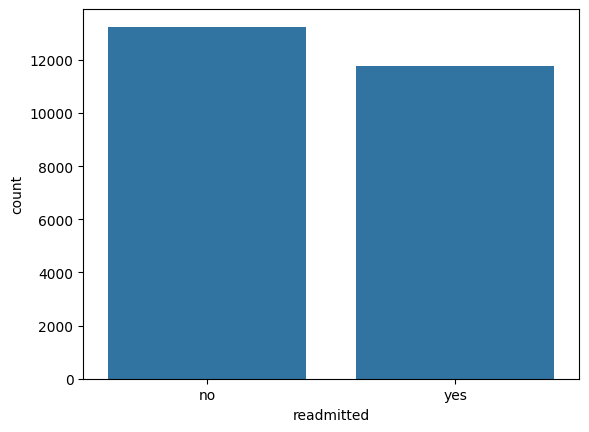

In [4]:
df.info()
df.describe()
df.isnull().sum()

df['readmitted'].value_counts(normalize=True)*100

import seaborn as sns
sns.countplot(x='readmitted', data=df)
print(df['readmitted'].value_counts(normalize=True)*100)

# Data Preprocessing


- **Categorical encoding** - models need numbers, so the 9 text columns are converted with `LabelEncoder`
  (alphabetical order → 0, 1, 2, …). `"Missing"` is kept as its own category (dropping rows would lose data,
  and missingness itself may carry signal).
- One encoder **per column** (number 0 means something different in each column), stored in `encoders`
  so numbers can be converted back, or a new patient encoded the same way.
- **Known limitation** - LabelEncoder creates a fake order (e.g. glucose: high=0, no=1, normal=2).
  Fine for binary columns and `age`; not meaningful for `diag_1-3` / `medical_specialty` in Logistic Regression.
  One-hot encoding would fix this. Random Forest is less affected.
- **Target encoding** - `{"no": 0, "yes": 1}` set explicitly, so **1 = readmitted is the positive class**
  (recall = share of readmitted patients we catch).

In [6]:
#import the OneHotEncoder tool used to convert text columns into numeric columns
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

#list of the 9 categorical (text) columns that need to be converted to numbers
categorical_cols = ["age", "medical_specialty", "diag_1", "diag_2", "diag_3",
                    "glucose_test", "A1Ctest", "change", "diabetes_med"]

#create an empty dictionary to store each column's own encoder
#in case we need to convert numbers back to their original text values later
encoders = {}

#loop through each column name in the list above, one column at a time
for col in categorical_cols:

  #create a NEW, seperate encoder for this column
  #drop="first": drops one category, since it can be inferred from the others
  #sparse_output=False: return a normal table instead of a compressed one
  ohe = OneHotEncoder(drop="first", sparse_output=False)

  #.fit() the encoder learn all the distinct text values in column
  #.transform(): creates a separate 0/1 column for each value, instead of one number per value
  #(LabelEncoder's 0,1,2,... wrongly implied an order between categories)
  new_values = ohe.fit_transform(df[[col]])

  #name the new columns e.g. diag_1 -> diag_1_Diabetes, diag_1_Respiratory, ...
  new_cols = pd.DataFrame(new_values, columns=ohe.get_feature_names_out([col]),
                          index=df.index).astype(int)

  #replace the original text column with the new 0/1 columns
  df = pd.concat([df.drop(columns=col), new_cols], axis=1)

  #store this column's encoder in the 'encoders' dictionary, labeled by column name
  #so it can be used later to reverse the mapping 0/1 columns -> original text
  encoders[col] = ohe

#check the new number of columns (was 17 before)
print(df.shape)

(25000, 46)


In [7]:
df["readmitted"] = df["readmitted"].map({"no": 0, "yes": 1})

# Train / Validation / Test Split
- **Train 70%** (learn) · **Validation 15%** (compare models, explore thresholds) · **Test 15%** (used once, at the end).
- `stratify` keeps the 53/47 ratio in every set; `random_state=42` makes the split reproducible.
- Second split uses 0.1765 because it splits the remaining 85%: 15 / 85 = 0.1765.

In [8]:
#import the tool used to split a dataset into separate subnets
from sklearn.model_selection import train_test_split

#separate the input features X from the target label Y
X = df.drop(columns=["readmitted"])
y = df["readmitted"]

#step 1: split off 15% as the test set, kept untouched until final evaluation
#stratify = y keeps the same yes/no ratio in both parts
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

#step 2: split the remaining 85% into train(70%) and validation (15%)
#0.1765 of 85% = 15% of the original total, so final split is 70/15/15
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42
)

#check the size of each subnet to confirm the split worked as expected
print(X_train.shape, X_val.shape, X_test.shape)

(17499, 45) (3751, 45) (3750, 45)


# Logistic Regression (main model)
Input Variables - all 16 encoded features $x_1,\dots,x_{16}$

Hypothesis - $p = \sigma(z) = \dfrac{1}{1+e^{-z}}$, with $z = w_1x_1 + \dots + w_{16}x_{16} + b$
→ $w$ = `model.coef_`, $b$ = `model.intercept_`, $\sigma$ inside `predict_proba`; `predict` returns 1 if $p \ge 0.5$

Loss Function - binary cross-entropy $L = -\frac1n\sum\big[y_i\ln p_i + (1-y_i)\ln(1-p_i)\big]$
. Computed inside `.fit()`. Punishes confident wrong predictions heavily;
convex for this model → one global minimum.

Optimisation Algorithm - `lbfgs` (sklearn default), quasi-Newton version of gradient descent
$w \leftarrow w - \alpha\, H\, \nabla L$: follows the slope and uses estimated curvature to pick the step size.
`max_iter=1000` because the default 100 gave a convergence warning (unscaled features).

Why this model - binary tabular task, and **interpretable**: each weight shows direction and size of effect,
so a clinician can see *why* a patient is flagged.

In [9]:
from sklearn.linear_model import LogisticRegression
#step 1 choose the hypothese space H - nothing learn yet
model = LogisticRegression(max_iter = 1000, random_state=42)
#step 2 learn h ∈ H: lbfgs minimises cross-entropy on 17,499 training records
model.fit(X_train, y_train)

print("Number of features: ", X_train.shape[1])
print("Learned weights (coefficients): ", model.coef_)  #16 weights, same order as X_train.column
print("Learned intercept (bias term): ", model.intercept_) #sigmoid = 34% when all feature = 0

Number of features:  45
Learned weights (coefficients):  [[ 0.01568869  0.00298378 -0.04065507  0.00205913  0.11917374  0.38346904
   0.23346015 -0.00506629  0.12301089  0.17853734  0.2382864  -0.10014008
   0.13130889 -0.01814956 -0.15927618  0.06960488 -0.14399455 -0.2722001
   0.18188913  0.05560413 -0.16557113 -0.09535502 -0.16516733 -0.15586697
  -0.04010931 -0.05065789 -0.20569467 -0.13693122  0.16217299  0.02544642
  -0.11015336 -0.1046112   0.00633159  0.07847928 -0.1163819  -0.57451094
   0.0250298  -0.05805073 -0.00627929 -0.07833378  0.02710458  0.16040212
  -0.04436179  0.04775894  0.24659142]]
Learned intercept (bias term):  [-0.83923545]


# Quick Validation Check
- Validation set, not test: test is kept for one final, unbiased evaluation.
- `predict` cuts the probability at 0.5. Accuracy 0.6073 = (1571 + 707) / 3751 → ~8 points above the 53% baseline.

In [10]:
from sklearn.metrics import accuracy_score

y_val_pred = model.predict(X_val) #0/1 prediction (threshold 0.5)
val_accuracy = accuracy_score(y_val, y_val_pred) #correct total

print(f"Validation accuracy: {val_accuracy: .4f}")

Validation accuracy:  0.6108


# Visualising the Sigmoid Decision Boundary
- The full model has 16 features and cannot be drawn, so a **separate 1-feature model** on `n_inpatient`
  (strongest feature) is fitted **only for visualisation**.
- Dots = real patients (0 or 1). Green curve = predicted probability: S-shaped, always between 0 and 1.
- **Decision boundary** = where the curve crosses the threshold (0.5) → about 0.8 prior visits:
  0 visits → "no", ≥ 1 visit → "yes". Lowering the threshold moves the cut-off left → more patients flagged.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


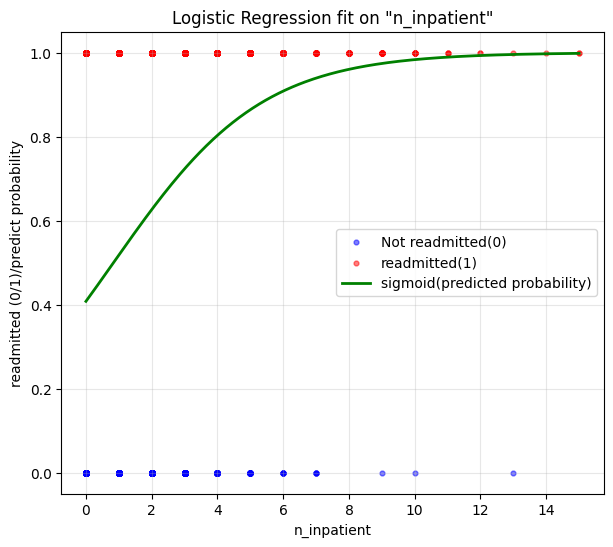

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

feature_name = "n_inpatient"
X_single = X_train[[feature_name]]
model_single = LogisticRegression()
model_single.fit(X_single, y_train)

x_line = np.linspace(X_single[feature_name].min(), X_single[feature_name].max(), 300).reshape(-1,1)
y_prob = model_single.predict_proba(x_line)[:, 1]

plt.figure(figsize=(7,6))
plt.scatter(X_single[y_train==0], y_train[y_train==0], s=12, color='blue', label='Not readmitted(0)', alpha = 0.5)
plt.scatter(X_single[y_train==1], y_train[y_train==1], s=12, color='red', label='readmitted(1)', alpha = 0.5)
plt.plot(x_line, y_prob, color = 'green', linewidth=2, label='sigmoid(predicted probability)')
plt.xlabel(feature_name)
plt.ylabel('readmitted (0/1)/predict probability')
plt.title(f'Logistic Regression fit on "{feature_name}"')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Random Forest (comparison model)
Hypothesis - average of 200 decision trees; each tree is a sequence of yes/no questions, so the forest
**can capture interactions** that Logistic Regression cannot. Larger hypothesis space.

Training criterion - no single loss for the whole model: each split picks the question that most reduces
**Gini impurity** $1-(p_{yes}^2+p_{no}^2)$ (greedy, no gradient).

Randomness - each tree sees a bootstrap sample of patients and a random subset of features per split →
trees differ, averaging reduces overfitting.

Prediction - each tree gives the share of readmitted training patients in its leaf; `predict_proba` averages
the 200 values; `predict` cuts at 0.5.

Hyperparameters (chosen, not tuned):
- `n_estimators=200` - enough for the average to stabilise; more trees only cost time
- `max_depth=10` - limits each tree (≤ 1,024 leaves) so it does not memorise individual patients
- `random_state=42` - **does matter here** (random sampling) → reproducible results

In [12]:
#import the random forest model
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators= 200, #number of decision trees in the ensemble
    max_depth= 10, # max depth per tree, limits overfitting
    random_state = 42 #fixes randomness for reproducible results
)
rf_model.fit(X_train, y_train) #train the model on the training set

RandomForestClassifier(max_depth=10, n_estimators=200, random_state=42)

# Metric Comparison (validation set)
- One function scores **both models the same way** (and is reused for the test set).
- `y_pred` = 0/1 after cutting at 0.5 (like pass/fail) → Accuracy, Precision, Recall, F1.
- `y_prob` = raw probability (like the exam score) → **AUC**, which measures **ranking** and does not
  depend on the threshold.

| Metric | Question it answers | Formula |
|---|---|---|
| Accuracy | how many predictions are correct? | (TP+TN) / all |
| Precision | of the patients we flag, how many are really readmitted? (false alarms) | TP / (TP+FP) |
| Recall | of the readmitted patients, how many do we catch? (missed patients) | TP / (TP+FN) |
| F1 | balance of precision and recall | 2PR / (P+R) |
| AUC | P(random readmitted patient ranked above a random non-readmitted one) | uses probabilities |

**Key point** - accuracy is the same (~0.61), but RF has higher recall (0.47 vs 0.40) and LR higher precision
(0.63 vs 0.61). AUC differs by only ~0.01 → the limit is the data, not the model.

In [13]:
#import all metric functions
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

def evaluate_model(model, X, y_true):
  y_pred = model.predict(X) #class predictions (0 or 1), using threshold 0.5
  y_prob = model.predict_proba(X)[:, 1] #raw probability of class 1, needed for AUC-ROC
  return {
      "Accuracy": accuracy_score(y_true, y_pred), #overall % of correct predictions
      "Precision": precision_score(y_true, y_pred), #of predicted "1"s, % actually correct
      "Recall": recall_score(y_true, y_pred), #of real "1", % correctly caught
      "F1-score": f1_score(y_true, y_pred), #balance between Precision and Recall
      "AUC-ROC": roc_auc_score(y_true, y_prob), # overall ability to rank classes correctly

  }

results = {
    "Logistic Regression": evaluate_model(model, X_val, y_val), #evaluate model 1
    "Random Forest": evaluate_model(rf_model, X_val, y_val), #evaluate model 2
}

import pandas as pd
results_df = pd.DataFrame(results).T #covert results dict into a readable table
print(results_df) #display the comparison table

                     Accuracy  Precision    Recall  F1-score   AUC-ROC
Logistic Regression   0.61077   0.627946  0.422902  0.505420  0.638936
Random Forest         0.61157   0.616730  0.459751  0.526794  0.651656


# Confusion Matrix (validation, threshold 0.5)
Rows = true label, columns = prediction. Diagonal = correct. **Bottom-left = false negatives (missed
readmissions), the most costly error.**

| | TN | FP (false alarm) | FN (missed) | TP (caught) |
|---|---|---|---|---|
| Logistic Regression | 1571 | 416 | 1057 | 707 |
| Random Forest | 1446 | 541 | 929 | 835 |

Row totals are the same for both (1987 no, 1764 yes) because it is the same validation set.
RF catches **128 more** readmitted patients but raises **125 more** false alarms → at 0.5 it mostly flags more
people rather than ranking much better (consistent with the 0.01 AUC gap).

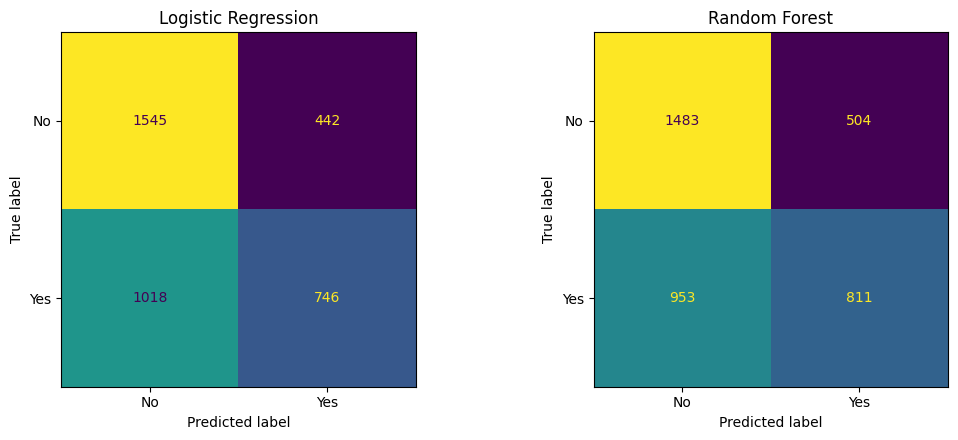

In [14]:
#import the matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5)) #create 2 side-by-side plots
for ax, (name, m) in zip(axes, [("Logistic Regression", model), ("Random Forest", rf_model)]):
  cm = confusion_matrix(y_val, m.predict(X_val)) #count correct/incorrect predictions
  ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(ax=ax, colorbar = False) #draw it
  ax.set_title(name) #label each subplot with the model name
plt.tight_layout() #avoid overlapping labels
plt.show() #render the figure

# Threshold Tuning (Logistic Regression, validation)
- At 0.5, recall is only 0.40 → 60% of readmitted patients are missed. Missing a patient costs more than an extra call.
- The model is **not retrained**: the same probabilities are cut at a lower threshold → more patients flagged.
- AUC is not in the table: it does not change with the threshold.

| Threshold | Precision | Recall | Patients flagged (of 3,751) |
|---|---|---|---|
| 0.5 | 0.63 | 0.40 | 1,123 (30%) |
| 0.4 | 0.53 | 0.76 | 2,529 (67%) |
| 0.3 | 0.47 | 0.99 | 3,692 (98%) |
| 0.2 | 0.47 | 1.00 | 3,751 (100%) |

- At 0.2 precision = 0.47 = base rate → the model flags **everyone** (same as having no model).
- F1 is highest at 0.2 **only because** flagging everyone already gives F1 = 0.64 → F1 alone cannot pick the threshold.
- Useful range ≈ 0.4–0.5, chosen by how many patients the hospital can follow up. 0.5 kept for the final table
  (same cut-off for both models); comparison relies mainly on AUC.

In [15]:
thresholds = [0.5, 0.4, 0.3, 0.2] #list of threholds to test
y_prob_val = model.predict_proba(X_val)[:, 1] #raw predicted probabilities (not yet thresholded)

threshold_results = []
for t in thresholds: #loop through each threshold
  y_pred_t = (y_prob_val >= t).astype(int) #apply threshold t manually -> 0/1 labels
  threshold_results.append({
      "Threshold": t, #record the threshold used
      "Precision": precision_score(y_val, y_pred_t), #precision at this threshold
      "Recall": recall_score(y_val, y_pred_t), # recall at this threshold
      "F1-score": f1_score(y_val, y_pred_t), #f1 at this threshold
  })

threshold_df = pd.DataFrame(threshold_results) #covert list of results into a table
print(threshold_df) #display the table

   Threshold  Precision    Recall  F1-score
0        0.5   0.627946  0.422902  0.505420
1        0.4   0.532462  0.762472  0.627040
2        0.3   0.476591  0.963719  0.637779
3        0.2   0.471028  1.000000  0.640407


# Feature Importance (Random Forest)
- Importance = how much a feature reduces Gini impurity, summed over all splits and 200 trees, normalised to sum to 1.
- **n_inpatient ≈ 0.22**, about twice the next feature, and also the largest weight in Logistic Regression
  → two different models agree on the strongest signal.
- Limits: shows **no direction** (LR coefficients do); impurity importance **favours features with many values**
  (n_lab_procedures, n_medications rank high here but have ~0 weight in LR); computed on training data.
  Permutation importance on validation would be fairer.
- Note: the x-axis is the importance score (label should read "Importance").

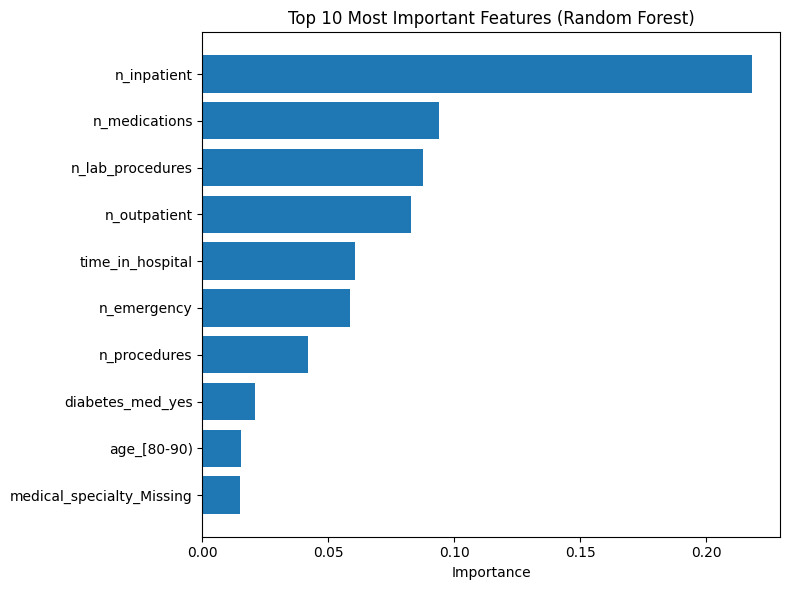

In [16]:
import numpy as np

importances = rf_model.feature_importances_ #importance score per feature (from RF)
feature_name = X_train.columns #get the actual column names
sorted_idx = np.argsort(importances)[::-1] #get indices sorted from most to least important

plt.figure(figsize=(8,6))
plt.barh(feature_name[sorted_idx][:10][::-1], importances[sorted_idx][:10][::-1]) #top 10 features name
#their corresponding importance scores
plt.xlabel("Importance") #label the x-axis
plt.title("Top 10 Most Important Features (Random Forest)") #chart title
plt.tight_layout()
plt.show()

# Cross-Validation (5-fold, stratified)
- Checks that results do not depend on **one lucky split**. Run on train + validation (21,250 records); **test untouched**.
- Each fold: train a fresh copy on 4/5, score on 1/5; every record is tested exactly once. mean = typical score,
  std = variation across folds.

| Model | AUC mean ± std | Accuracy mean ± std | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression | 0.642 ± 0.004 | 0.608 ± 0.005 | 0.40 | 0.49 |
| Random Forest | 0.656 ± 0.004 | 0.615 ± 0.006 | 0.48 | 0.54 |

- AUC gap 0.014 ≈ 3–4 × the std → RF's ranking advantage is **real but small**.
- Accuracy gap ≈ the std → cannot separate the models on accuracy.
- Means match the single validation split → results are stable.

In [17]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
#5folds keep the 53/47 class ratio in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state= 42)
#metrics to compute on each fold
scoring= {"Accuracy": "accuracy", "recall": "recall", "f1":"f1", "auc":"roc_auc"}

#same setting as models trained earlier
cv_models ={
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1),
}

cv_rows={}
for name, est in cv_models.items():
  #train + validation data only, the test is note used
  res = cross_validate(est, X_temp, y_temp, cv=cv, scoring=scoring, n_jobs=1)
  # mean = typical score, std = variation acrross the 5 folds
  cv_rows[name] = {
      "AUC mean": res["test_auc"].mean(), "AUC std": res["test_auc"].std(),
      "Accuracy mean": res["test_Accuracy"].mean(), "Accuracy std": res["test_Accuracy"].std(),
      "Recall mean": res["test_recall"].mean(), "F1 mean":res["test_f1"].mean(),
  }

cv_df = pd.DataFrame(cv_rows).T.round(4) # one row per model
print(cv_df)



                     AUC mean  AUC std  Accuracy mean  Accuracy std  \
Logistic Regression    0.6441   0.0054         0.6104        0.0050   
Random Forest          0.6564   0.0047         0.6149        0.0059   

                     Recall mean  F1 mean  
Logistic Regression       0.4133   0.4993  
Random Forest             0.4685   0.5336  


# Final Test Evaluation (used once)
- Same `evaluate_model` function on the held-out test set (3,750 records), threshold 0.5.
- Test results are within ~0.015 of validation for both models → no overfitting to the validation set.

In [ ]:
#run this cell only once, after all model/threshold decision are finalized
final_results = {
    "Logistic Regression": evaluate_model(model, X_test, y_test), #final one time
    "Random Forest": evaluate_model(rf_model, X_test, y_test),
}
final_results_df = pd.DataFrame(final_results).T #convert to a readable table
print(final_results_df) #display the table

                     Accuracy  Precision    Recall  F1-score   AUC-ROC
Logistic Regression    0.6072    0.62697  0.406126  0.492943  0.642998
Random Forest          0.6160    0.61544  0.488372  0.544592  0.653236
